# Dictionary Learning pour la reconstruction de données manquantes

L’idée est de représenter des fenêtres temporelles de plusieurs capteurs avec un petit ensemble d’atomes appris automatiquement.  
Chaque fenêtre est codée de façon parcimonieuse, puis reconstruite à partir du dictionnaire.  
Si la valeur cible est manquante, on peut la reconstruire à partir des autres signaux observés et de la base apprise.

## Pourquoi cela est utile
- Les séries industrielles sont souvent corrélées entre capteurs.
- Un dictionnaire appris sur des fenêtres glissantes capture des motifs répétitifs.
- La reconstruction reste robuste même quand certaines valeurs sont absentes.

## Plan du notebook
1. Charger et préparer les données.
2. Définir une classe Python de reconstruction par dictionary learning.
3. Entraîner le modèle sur des fenêtres temporelles.
4. Évaluer la reconstruction sur des valeurs masquées artificiellement.

In [8]:
from __future__ import annotations

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.decomposition import MiniBatchDictionaryLearning, sparse_encode
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

In [9]:
# Chemin vers votre fichier CSV
path = Path(r"C:\Users\camelia\Documents\letsgo\industrial-vibration-missing-data-reconstruction\data\processed\synthetic_A_sensor.csv")

# Lecture du fichier : le fichier utilise des décimales avec virgule
# et des colonnes séparées par des virgules.
df = pd.read_csv(path, sep=",", decimal=",")

# Conversion de la colonne temporelle
if "Timestamp" in df.columns:
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], utc=True)
    df = df.sort_values("Timestamp").reset_index(drop=True)

print(df.head())
print("\nColonnes disponibles :")
print(df.columns.tolist())
print("\nForme du dataframe :", df.shape)

                  Timestamp  A_ACR_Mot.PV  A_ACR_Mot.SV  A_ACR_Mot.TV  \
0 2024-10-30 10:30:00+00:00      0.002195      3.501408     45.368494   
1 2024-10-30 10:30:01+00:00      0.002260      3.100835     45.507269   
2 2024-10-30 10:30:02+00:00      0.002224      3.128099     45.404132   
3 2024-10-30 10:30:03+00:00      0.002231      2.906540     45.570477   
4 2024-10-30 10:30:04+00:00      0.002168      3.028329     45.822234   

   A_ACR_Pmp.PV  A_ACR_Pmp.SV  A_ACR_Pmp.TV           A_Pres.PV  A_Temp.PV  \
0      0.001687     13.744211     38.154256  19.572690575396347  38.710390   
1      0.001754     13.288506     38.276253  19.600693610180542  38.989240   
2      0.001666     13.259763     38.183900  18.741180764855994  39.137690   
3      0.001325     13.637371     38.174162  15.755143584847739  39.905897   
4      0.001461     12.508879     38.034020   20.58975988471463  38.955740   

     Barometer  Temperature  
0  1020.259978    23.126361  
1  1020.270705    23.098901  
2 

In [10]:
# Choix d'une variable cible et de plusieurs prédicteurs
# Vous pouvez changer facilement cette configuration selon votre besoin.
target = "A_ACR_Mot.TV"
predictors = [
    col for col in df.columns
    if col not in {"Timestamp", target} and pd.api.types.is_numeric_dtype(df[col])
]

# Garder uniquement les colonnes utiles
model_df = df[["Timestamp", target] + predictors].copy()

# Remplacer les valeurs manquantes éventuelles par une interpolation simple
model_df = model_df.ffill().bfill()

print("Cible :", target)
print("Prédicteurs :")
print(predictors)
print("\nAperçu du dataframe préparé :")
print(model_df.head())

Cible : A_ACR_Mot.TV
Prédicteurs :
['A_ACR_Mot.PV', 'A_ACR_Mot.SV', 'A_ACR_Pmp.PV', 'A_ACR_Pmp.SV', 'A_ACR_Pmp.TV', 'A_Temp.PV', 'Barometer', 'Temperature']

Aperçu du dataframe préparé :
                  Timestamp  A_ACR_Mot.TV  A_ACR_Mot.PV  A_ACR_Mot.SV  \
0 2024-10-30 10:30:00+00:00     45.368494      0.002195      3.501408   
1 2024-10-30 10:30:01+00:00     45.507269      0.002260      3.100835   
2 2024-10-30 10:30:02+00:00     45.404132      0.002224      3.128099   
3 2024-10-30 10:30:03+00:00     45.570477      0.002231      2.906540   
4 2024-10-30 10:30:04+00:00     45.822234      0.002168      3.028329   

   A_ACR_Pmp.PV  A_ACR_Pmp.SV  A_ACR_Pmp.TV  A_Temp.PV    Barometer  \
0      0.001687     13.744211     38.154256  38.710390  1020.259978   
1      0.001754     13.288506     38.276253  38.989240  1020.270705   
2      0.001666     13.259763     38.183900  39.137690  1020.224882   
3      0.001325     13.637371     38.174162  39.905897  1020.212361   
4      0.001461   

In [11]:
class DictionaryReconstructor:
    """Reconstruction de valeurs manquantes à partir d'un dictionnaire appris sur des fenêtres temporelles."""

    def __init__(
        self,
        window_size: int = 10,
        n_components: int = 16,
        alpha: float = 0.1,
        max_iter: int = 500,
        seed: int = 42,
    ) -> None:
        self.window_size = window_size
        self.n_components = n_components
        self.alpha = alpha
        self.max_iter = max_iter
        self.seed = seed
        self.model: MiniBatchDictionaryLearning | None = None
        self.target = ""
        self.predictors: list[str] = []

    def _matrix(self, data: pd.DataFrame, include_target: bool) -> tuple[np.ndarray, list[np.ndarray]]:
        cols = self.predictors + ([self.target] if include_target else [])
        matrix, indices = [], []
        for end in range(self.window_size - 1, len(data)):
            block = data.iloc[end - self.window_size + 1:end + 1][cols].to_numpy(dtype=float).T
            if include_target and not np.isfinite(block).all():
                continue
            matrix.append(block.ravel())
            indices.append(np.arange(end - self.window_size + 1, end + 1))
        return np.asarray(matrix, dtype=float), indices

    def fit(self, train: pd.DataFrame, target: str, predictors: list[str]) -> "DictionaryReconstructor":
        self.target, self.predictors = target, predictors
        samples, _ = self._matrix(train, include_target=True)
        if len(samples) < self.n_components:
            raise ValueError("Pas assez de fenêtres complètes pour apprendre un dictionnaire.")

        self.model = MiniBatchDictionaryLearning(
            n_components=self.n_components,
            alpha=self.alpha,
            max_iter=self.max_iter,
            batch_size=min(256, len(samples)),
            random_state=self.seed,
        )
        self.model.fit(samples)
        return self

    def predict(self, data: pd.DataFrame) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        if self.model is None:
            raise RuntimeError("Le modèle n'a pas encore été entraîné.")

        prior = np.full(len(data), np.nan)
        variance = np.full(len(data), np.nan)
        availability = np.full(len(data), np.nan)
        dictionary = self.model.components_
        channels = len(self.predictors) + 1

        for end in range(self.window_size - 1, len(data)):
            block = data.iloc[end - self.window_size + 1:end + 1][self.predictors + [self.target]].to_numpy(dtype=float).T
            observed = np.isfinite(block)
            pred_available = observed[:-1].all(axis=1)
            availability[end] = pred_available.sum()

            if pred_available.sum() < 2:
                continue

            # La valeur cible actuelle est volontairement masquée lors de la prédiction.
            observed[-1, -1] = False
            flat = block.ravel()
            mask = observed.ravel()

            if not mask.any():
                continue

            coefficients = sparse_encode(
                flat[mask][None, :],
                dictionary[:, mask],
                algorithm="lasso_lars",
                alpha=self.alpha,
            )
            reconstructed = coefficients @ dictionary
            target_index = (channels - 1) * self.window_size + self.window_size - 1
            prior[end] = reconstructed[0, target_index]
            residual = flat[mask] - reconstructed[0, mask]
            variance[end] = max(float(np.mean(residual**2)), 1e-6)

        return prior, variance, availability

In [12]:
# Séparation train / validation
train_size = int(len(model_df) * 0.8)
train_df = model_df.iloc[:train_size].copy()
valid_df = model_df.iloc[train_size:].copy()

# Masquage artificiel de certaines valeurs cibles pour l'évaluation
rng = np.random.default_rng(42)
valid_masked = valid_df.copy()
mask_positions = rng.choice(len(valid_masked), size=max(20, len(valid_masked) // 10), replace=False)
valid_masked.loc[valid_masked.index[mask_positions], target] = np.nan

# Entraînement
reconstructor = DictionaryReconstructor(
    window_size=10,
    n_components=16,
    alpha=0.1,
    max_iter=500,
    seed=42,
)
reconstructor.fit(train_df, target=target, predictors=predictors)

# Prédiction sur les données avec valeurs masquées
prior, variance, availability = reconstructor.predict(valid_masked)

# Extraction des positions réellement masquées
masked_idx = np.where(valid_masked[target].isna())[0]
true_values = valid_df[target].to_numpy()[masked_idx]
pred_values = prior[masked_idx]

# Garder seulement les prédictions valides
valid_predictions = np.isfinite(pred_values) & np.isfinite(true_values)
true_values = true_values[valid_predictions]
pred_values = pred_values[valid_predictions]

print("Nombre de valeurs masquées évaluées :", len(true_values))
print("MAE :", mean_absolute_error(true_values, pred_values))
print("RMSE :", np.sqrt(mean_squared_error(true_values, pred_values)))
print("Variance moyenne :", np.nanmean(variance[masked_idx]))

Nombre de valeurs masquées évaluées : 432
MAE : 0.8158070600809834
RMSE : 1.3621141031172337
Variance moyenne : 0.3728556194334705


In [ ]:
# Diagnostic sur les changements brusques d'intensité
# On masque artificiellement les points les plus abrupts de la cible et on mesure
# si le modèle les reconstruit à partir des autres capteurs.

# 1) Détection d'une pseudo-rupture : grands écarts entre deux instants successifs
series = valid_df[target].astype(float).to_numpy()
diff_abs = np.abs(np.diff(series))
q95 = np.quantile(diff_abs[~np.isnan(diff_abs)], 0.95)
abrupt_candidates = np.where(diff_abs >= q95)[0]

# 2) Masquage de quelques points abrupts pour évaluation
n_eval = min(20, len(abrupt_candidates))
abrupt_idx = abrupt_candidates[:n_eval]

abrupt_test = valid_df.copy()
abrupt_test.loc[abrupt_test.index[abrupt_idx], target] = np.nan

prior_abrupt, _, _ = reconstructor.predict(abrupt_test)
pred_abrupt = prior_abrupt[abrupt_idx]
true_abrupt = valid_df[target].to_numpy()[abrupt_idx]
valid_abrupt = np.isfinite(pred_abrupt) & np.isfinite(true_abrupt)

print("Seuil de variation brutale (Q95 des abs diff) :", round(float(q95), 6))
print("Nombre de points abrupts testés :", int(valid_abrupt.sum()))
if int(valid_abrupt.sum()) > 0:
    print("MAE sur points abrupts :", round(float(mean_absolute_error(true_abrupt[valid_abrupt], pred_abrupt[valid_abrupt])), 6))
    print("RMSE sur points abrupts :", round(float(np.sqrt(mean_squared_error(true_abrupt[valid_abrupt], pred_abrupt[valid_abrupt]))), 6))

# 3) Vérifier si les autres capteurs sont corrélés à la cible
corrs = []
for col in predictors:
    try:
        corr = float(valid_df[target].astype(float).corr(valid_df[col].astype(float)))
    except Exception:
        continue
    corrs.append((col, corr))

corrs = sorted(corrs, key=lambda x: abs(x[1]), reverse=True)
print("\nTop corrélations avec la cible :")
for col, corr in corrs[:8]:
    print(f"- {col}: {corr:.3f}")


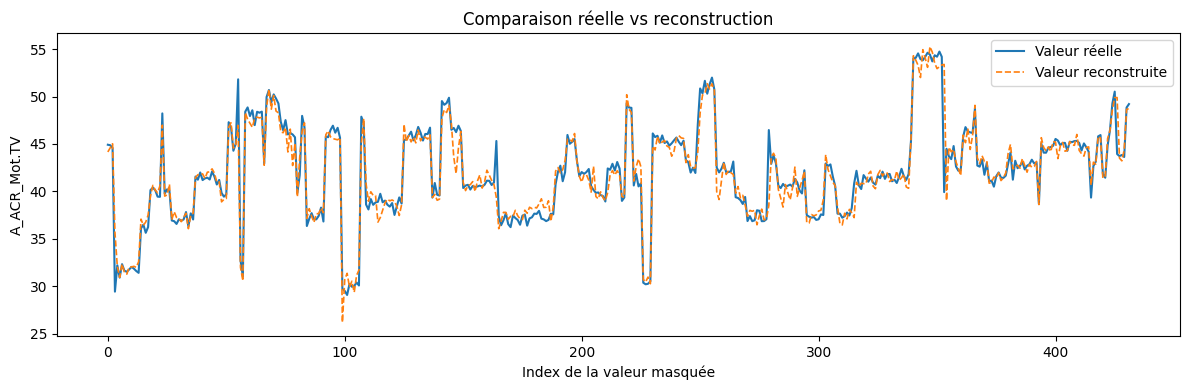

In [13]:
# Visualisation des prédictions sur quelques points
a = np.arange(len(true_values))
plt.figure(figsize=(12, 4))
plt.plot(a, true_values, label="Valeur réelle", color="tab:blue", linewidth=1.5)
plt.plot(a, pred_values, label="Valeur reconstruite", color="tab:orange", linestyle="--", linewidth=1.2)
plt.xlabel("Index de la valeur masquée")
plt.ylabel(target)
plt.title("Comparaison réelle vs reconstruction")
plt.legend()
plt.tight_layout()
plt.show()

## Interprétation

Le modèle apprend ici un dictionnaire de motifs temporels à partir de fenêtres glissantes.  
Lorsqu’une valeur est absente, il cherche une combinaison parcimonieuse d’atomes déjà observés pour reconstruire la fenêtre complète.

### Conseils pour aller plus loin
- Augmentez la taille de la fenêtre si vous voulez capturer des motifs plus longs.
- Ajustez le nombre de composants si vous souhaitez plus ou moins de capacité de représentation.
- Testez plusieurs cibles et différents ensembles de prédicteurs.
- Si vous disposez d’un vrai défaut de capteur, vous pouvez remplacer le masquage artificiel par des valeurs réellement manquantes.

### À retenir
- Le dictionary learning est intéressant pour des séries temporelles multivariées.
- Il fonctionne bien quand les signaux partagent des structures communes.
- La reconstruction est plus robuste si les fenêtres contiennent suffisamment d’informations observées.